# Support Vector Machines

Support Vector Machines are a bundle of tools that can be used to do a few different things
- Support vector regression (SVR) - for regression tasks - Fits a tube of width ε around the data; only points outside the tube count toward the loss 
- Support vector classification (SVC) - for classification tasks - Separates classes with the widest margin; handles multiple classes via one-vs-one or one-vs-rest
- One-class SVM - for anomaly detection - Learns a boundary around “normal” data and flags points outside it
- Clustering - Uses a one-class boundary in kernel space; disconnected regions become clusters
- Ranking - Learns an ordering from pairs (“A should rank above B”) rather than labels
- Feature selection - Repeatedly removes features with the smallest weights, or drives weights to zero

The main features that are common to all these sub-techniques of SVMs are **maximum-margin objective** and the **kernel trick**. 

So, once you understand how these two work, you will be able to follow how they are used to achieve the different goals listed above.

For the purpose of this course, we will focus on **classification**.

## Support Vector Classifier

*Drawing the best possible line between two groups - and a clever trick for when a line isn't enough.*

:::{admonition} What we are going to do
:class: tip
So far we have mostly **predicted a number**: a hardness, a formation energy, a property with error bars. This chapter (and the next one) does something different - it puts each sample into a **class** ("this is a metal", "this is a ceramic", "this is a defect" etc.).

A **Support Vector Classifier (SVC)** does this by drawing a boundary between the groups. But we don't just draw *a* boundary - we draw the one with the **widest safety gap**. When a straight boundary won't fit, a trick called the **kernel** comes to the rescue.
:::

## Why this is different to what we have done so far

Trace where we have been. Linear regression, Ridge, Lasso, Gaussian Processes - all of them answered *"what number?"* Give the model an input, get a value out.

Now we ask a different question:

> *"Which **group** does this sample belong to?"*

Is this glass a window pane or a headlamp? Is this sample a defect or a good part? That is **classification**, and Support Vector Machines are one -of the friendliest, most powerful ways to do it. The whole idea starts with a very human instinct: **draw a line between the two groups - and leave as much breathing room as you can.**

## Start simple: one feature, one boundary

Imagine we measure a single property - say, density - for two kinds of material. Class A has low density, Class B has high density, and (lucky us) they don't overlap.

Where should the boundary go? Anywhere in the gap would separate them. But the *safest* choice is right in the **middle**, as far as possible from both groups. That gives us the widest **margin** - the most breathing room before we risk a mistake.

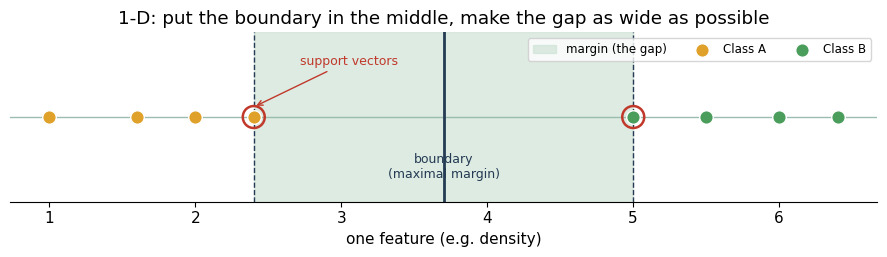

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_blobs, make_circles
from matplotlib.colors import ListedColormap

plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False})
GOLD, GREEN, LINE, SV, MARGIN = "#e0a12a", "#4a9d5b", "#243b53", "#c0392b", "#cfe3d6"
PTS = {0:GOLD, 1:GREEN}
def scatter2d(ax, X, y):
    for c,col in PTS.items():
        ax.scatter(X[y==c,0], X[y==c,1], color=col, edgecolor="white", lw=0.6, s=45, zorder=3)
def draw_boundary(ax, clf):
    xx=np.linspace(*ax.get_xlim(),300); yy=np.linspace(*ax.get_ylim(),300)
    XX,YY=np.meshgrid(xx,yy); Z=clf.decision_function(np.c_[XX.ravel(),YY.ravel()]).reshape(XX.shape)
    ax.contour(XX,YY,Z, levels=[-1,0,1], colors=LINE, linestyles=["--","-","--"], linewidths=[1,2,1])
def draw_regions(ax, clf):
    xx=np.linspace(*ax.get_xlim(),300); yy=np.linspace(*ax.get_ylim(),300)
    XX,YY=np.meshgrid(xx,yy); Z=clf.predict(np.c_[XX.ravel(),YY.ravel()]).reshape(XX.shape)
    ax.contourf(XX,YY,Z, alpha=0.15, cmap=ListedColormap([GOLD,GREEN]), zorder=0)
def circle_sv(ax, clf):
    ax.scatter(clf.support_vectors_[:,0],clf.support_vectors_[:,1], s=170,
               facecolors="none", edgecolors=SV, linewidths=1.8, zorder=4)

gold=np.array([1.0,1.6,2.0,2.4]); green=np.array([5.0,5.5,6.0,6.4])
b=(2.4+5.0)/2
fig, ax = plt.subplots(figsize=(9,2.7))
ax.axvspan(2.4,5.0, color=MARGIN, alpha=0.7, label="margin (the gap)")
ax.axhline(0, color="#9bbdb0", lw=1)
ax.scatter(gold, np.zeros_like(gold), color=GOLD, edgecolor="white", s=95, zorder=3, label="Class A")
ax.scatter(green, np.zeros_like(green), color=GREEN, edgecolor="white", s=95, zorder=3, label="Class B")
ax.axvline(b, color=LINE, lw=2)
ax.axvline(2.4, color=LINE, lw=1, ls="--"); ax.axvline(5.0, color=LINE, lw=1, ls="--")
for xv in (2.4,5.0):
    ax.scatter([xv],[0], s=250, facecolors="none", edgecolors=SV, linewidths=1.8, zorder=4)
ax.annotate("support vectors", xy=(2.4,0.05), xytext=(3.05,0.26), fontsize=9, color=SV,
            ha="center", arrowprops=dict(arrowstyle="->", color=SV))
ax.text(b, -0.30, "boundary\n(maximal margin)", ha="center", fontsize=9, color=LINE)
ax.set_yticks([]); ax.set_ylim(-0.42,0.42); ax.set_xlabel("one feature (e.g. density)")
ax.spines["left"].set_visible(False); ax.legend(loc="upper right", fontsize=8.5, ncol=3)
ax.set_title("1-D: put the boundary in the middle, make the gap as wide as possible")
plt.tight_layout(); plt.show()


This middle-of-the-gap boundary is the **maximal margin classifier**. Notice the two circled points: they sit right on the edge of the margin and single-handedly decide where the boundary goes. Move any *other* point and nothing changes; move one of these and the boundary shifts. These special points are the **support vectors** - and they are where the method gets its name.

## Up a dimension (or several)

With **two** features, the boundary is no longer a point on a line - it becomes a **line** on a plane, with a margin on each side.

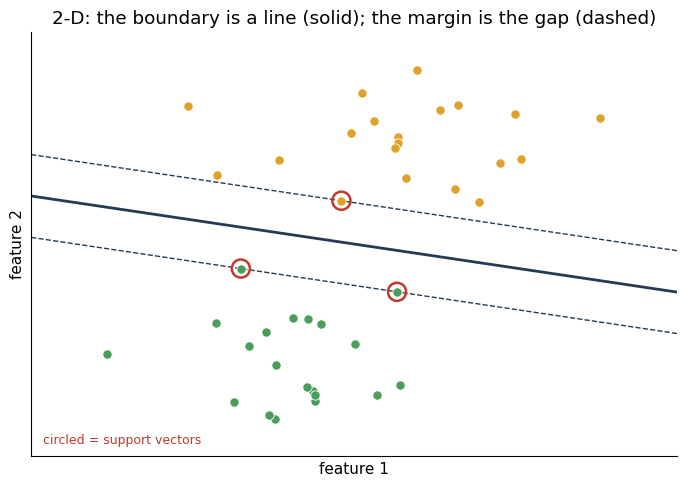

In [2]:
Xb, yb = make_blobs(n_samples=40, centers=2, cluster_std=1.05, random_state=6)
clf = SVC(kernel="linear", C=100).fit(Xb, yb)
fig, ax = plt.subplots(figsize=(7,5))
ax.set_xlim(Xb[:,0].min()-1, Xb[:,0].max()+1); ax.set_ylim(Xb[:,1].min()-1, Xb[:,1].max()+1)
scatter2d(ax, Xb, yb); draw_boundary(ax, clf); circle_sv(ax, clf)
ax.set_title("2-D: the boundary is a line (solid); the margin is the gap (dashed)")
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2"); ax.set_xticks([]); ax.set_yticks([])
ax.text(0.02,0.03,"circled = support vectors", transform=ax.transAxes, fontsize=9, color=SV)
plt.tight_layout(); plt.show()


The picture keeps its shape as we add features:

- **1 feature** → the boundary is a point.
- **2 features** → a line.
- **3 features** → a flat **plane** slicing through the cube of data.
- **4 or more features** → a **hyperplane** - we can't draw it, but the maths is exactly the same.

Good news for materials work, where you often have *many* descriptors at once: the method doesn't care how many features there are. The idea - *widest gap wins* - never changes.

You can use the interactive [hyperplane explorer](data\SVC_Hyperplane_explorer.html) to see how you can pick different planes and support vectors for both 2D and 3D.

The same idea carries forward to 4D and beyond, but of course we humans can't visualize them. However, computers don't have a problem with this because they will rely on calculations and not visualizations.

## Real data is messy: the soft margin

In the tidy examples above the groups sat far apart from each other. Real data can be a lot messier than that. Points overlap, and the odd sample lands on the wrong side.

If we *insist* on a boundary that separates the training data perfectly, we often end up with a very **narrow** margin squeezed around a couple of awkward points. That boundary fits today's data beautifully - and then wobbles badly on tomorrow's. Sound familiar? It is exactly the **bias–variance** trade-off from the last chapter.

The fix is wonderfully relaxed: **allow a few mistakes on purpose.** We let a handful of training points fall inside the margin (or even on the wrong side) in exchange for a **much wider, steadier** boundary. This relaxed version is called a **soft margin**, and it usually predicts new data better.

How relaxed should it be? That is set by a single knob called **C**:

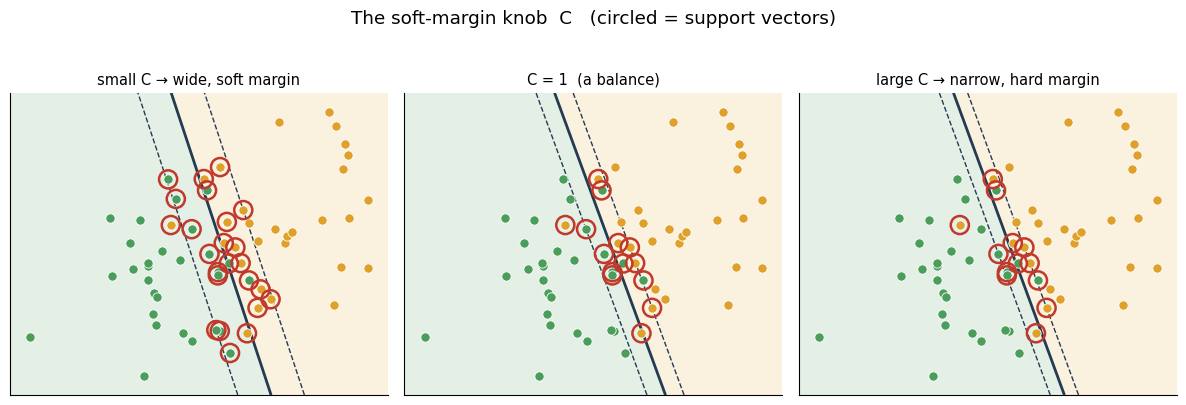

In [3]:
Xo,yo=make_blobs(n_samples=60,centers=2,cluster_std=2.6,random_state=3)
fig,axes=plt.subplots(1,3,figsize=(12,3.9),sharex=True,sharey=True)
labs=["small C \u2192 wide, soft margin","C = 1  (a balance)","large C \u2192 narrow, hard margin"]
for ax,Cv,lab in zip(axes,[0.05,1,100],labs):
    ax.set_xlim(Xo[:,0].min()-1,Xo[:,0].max()+1); ax.set_ylim(Xo[:,1].min()-1,Xo[:,1].max()+1)
    c=SVC(kernel="linear",C=Cv).fit(Xo,yo)
    draw_regions(ax,c); scatter2d(ax,Xo,yo); draw_boundary(ax,c); circle_sv(ax,c)
    ax.set_title(lab,fontsize=10.5); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("The soft-margin knob  C   (circled = support vectors)", y=1.03)
plt.tight_layout(); plt.show()


Read the three panels left to right:

- **Small C** → very relaxed → a **wide** margin with many support vectors. Simple and steady (more bias, less variance).
- **Large C** → strict → a **narrow** margin that tries hard to get every training point right (less bias, more variance).

:::{note} A neat connection
`C` is like the *opposite* of the penalty `λ` in Ridge and Lasso. A **big C** says "fit the training data hard" (less regularisation); a **small C** says "keep it simple" (more regularisation). Same tug-of-war, mirror-image knob.
:::

And how do we pick the best `C`? The same trusty tool as before: **cross-validation**. Try several values, keep the one that scores best on held-out data.

## The kernel

Here is a puzzle. Suppose one class sits in the *middle* and the other wraps *around* it. No straight line - no matter how you tilt it - you cannot separate them.

Think of a real world example: You bought some avocados, and left them on the table for them to ripen. If the $x$ scale is time, the green data shows 'the best time to eat'. Too soon and the fruits are not ripe yet, too late and they will be rotten.

Or this can be a drug dosage on the $x$ scale - too little and patient doesn't recover, too much and it will cause harm, but somewhere in the middle it can do its magic. 

The trick is beautiful. If the data can't be split in its current dimension, we **lift it into a higher one**, where a flat boundary *can* separate it. Watch the simplest possible example: one feature that we lift by adding a second feature equal to $x^2$.

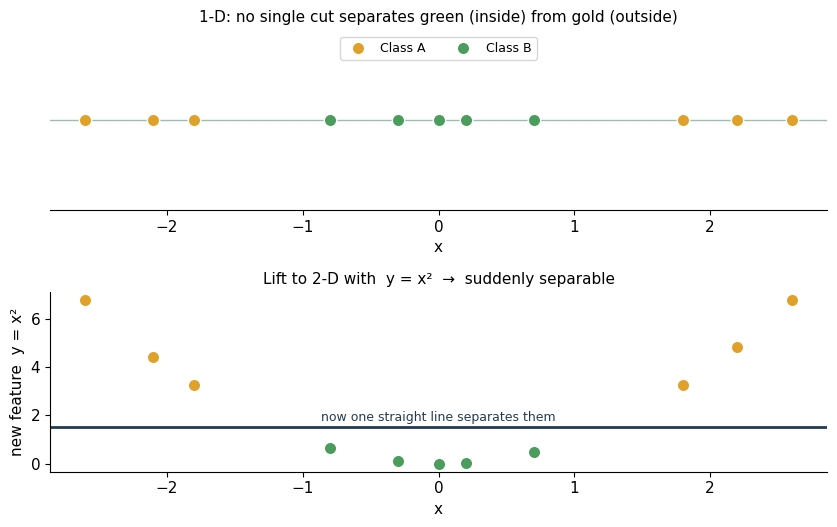

In [4]:
inner=np.array([-0.8,-0.3,0.0,0.2,0.7]); outer=np.array([-2.6,-2.1,-1.8,1.8,2.2,2.6])
fig,(t,bb)=plt.subplots(2,1,figsize=(8.5,5.4))
t.scatter(outer,np.zeros_like(outer),color=GOLD,edgecolor="white",s=80,zorder=3,label="Class A")
t.scatter(inner,np.zeros_like(inner),color=GREEN,edgecolor="white",s=80,zorder=3,label="Class B")
t.axhline(0,color="#9bbdb0",lw=1); t.set_yticks([]); t.set_ylim(-0.5,0.5)
t.set_title("1-D: no single cut separates green (inside) from gold (outside)",fontsize=11)
t.set_xlabel("x"); t.legend(fontsize=9,ncol=2,loc="upper center"); t.spines["left"].set_visible(False)
bb.scatter(outer,outer**2,color=GOLD,edgecolor="white",s=80,zorder=3)
bb.scatter(inner,inner**2,color=GREEN,edgecolor="white",s=80,zorder=3)
bb.axhline(1.5,color=LINE,lw=2)
bb.text(0.0,1.75,"now one straight line separates them",color=LINE,fontsize=9,ha="center")
bb.set_title("Lift to 2-D with  y = x\u00b2  \u2192  suddenly separable",fontsize=11)
bb.set_xlabel("x"); bb.set_ylabel("new feature  y = x\u00b2")
plt.tight_layout(); plt.show()


On the line (top) the green points are trapped between the gold ones - hopeless for a single cut. But once we add the new feature $y = x^2$ (bottom), the green points drop *low* and the gold points rise *high*, and a plain straight line separates them cleanly.

The function that lifts data into a higher dimension like this is called a **kernel**. And here is the genius part - the **kernel trick**:

> The computer never actually builds those high-dimensional coordinates. It only needs to measure **how similar each pair of points is**, and the kernel hands that over directly. So we get all the power of a high-dimensional separation, while paying only for low-dimensional maths.

Let's see it rescue a genuinely tangled 2-D dataset - rings inside rings:

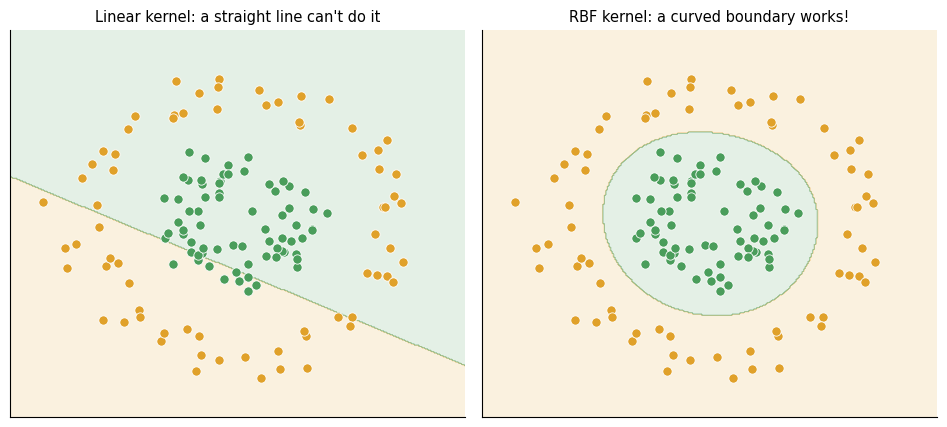

In [5]:
Xc,yc=make_circles(n_samples=140,factor=0.4,noise=0.10,random_state=0)
fig,(a1,a2)=plt.subplots(1,2,figsize=(9.6,4.4),sharex=True,sharey=True)
for ax,ker,lab in zip((a1,a2),["linear","rbf"],
                      ["Linear kernel: a straight line can't do it","RBF kernel: a curved boundary works!"]):
    ax.set_xlim(-1.5,1.5); ax.set_ylim(-1.5,1.5)
    c=SVC(kernel=ker,C=5,gamma=1.0).fit(Xc,yc)
    draw_regions(ax,c); scatter2d(ax,Xc,yc)
    ax.set_title(lab, fontsize=10.5); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()


The **linear** kernel (left) does its best and fails - no straight line can wrap around a ring. The **RBF** kernel (right) lifts the data and comes back with a smooth **curved** boundary that separates the rings perfectly.

You can see how this works in 3D using this **[interactive visualization](data\Kernel_life.html)**.

A few kernels you will meet:

- **Linear** - a plain straight boundary. Fast; great when the data is already roughly separable.
- **Polynomial** - curved boundaries via powers of the features (like our $x^2$ example).
- **RBF (radial basis function)** - the flexible all-rounder, and the usual default.

:::{note} Another familiar face
The RBF kernel has a setting called **gamma** that controls how far each point's influence reaches - small gamma gives a smooth boundary, large gamma a wiggly one. If that reminds you of the **length-scale** in Gaussian Processes, yes it's the very same idea.
:::

## The full recipe  🎂

Putting it together, an SVM works like this:

1. Start with your data.
2. (If needed) lift it to a higher dimension with a **kernel**.
3. Find the support vector classifier with the **widest margin** there.
4. **Try different kernels** (linear, polynomial, RBF…) and different settings of `C` and `gamma`.
5. Use **cross-validation** to pick the combination that generalises best.

Choosing `C`, `gamma`, and the kernel is just **hyperparameter search** - the same job as grid search and random search at the end of the last chapter (and exactly the kind of thing **Bayesian Optimization** can automate for you).

## Why SVMs suit materials science 🧪

SVMs are a particularly good match for materials problems:

- They work well with **small datasets** - and materials data is often small and hard-won.
- They handle **many features at once** - useful when each material has dozens of descriptors.
- With kernels, they cope with **non-linear** relationships - which are the norm, not the exception, in materials.

## Putting it to work 💪

Time to actually run one. A good SVC workflow has three habits worth building in from the start:

- **Scale the features first.** SVMs measure distances and margins, so a feature in big units would otherwise shout over the others. (Same lesson as clustering and Gaussian Processes - scaling keeps coming back!)
- **Split with `stratify=y`.** This keeps each class in the same proportion in the training and test sets - essential when one class is rare, so your test score isn't a fluke.
- **Use `class_weight="balanced"` for imbalanced data.** It tells the SVC to pay extra attention to the rare class. In materials this matters a lot: think of spotting the **defect** among mostly good parts, or the one **extraordinary** material among ordinary ones.

Here is the whole thing in a few lines (a small, made-up 3-class dataset so it runs on its own):

test accuracy: 0.821
              precision    recall  f1-score   support

           0       0.93      0.78      0.85        18
           1       0.86      0.80      0.83        15
           2       0.60      1.00      0.75         6

    accuracy                           0.82        39
   macro avg       0.80      0.86      0.81        39
weighted avg       0.85      0.82      0.83        39



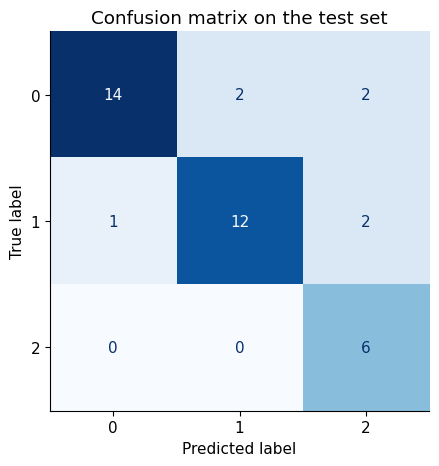

In [6]:
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- a small, made-up materials dataset: 3 classes, 2 descriptors, some imbalance ---
rng = np.random.default_rng(0)
centers, sizes = [(-2,-1),(2,-0.5),(0,2.5)], [70, 60, 25]     # class 2 is the rare one
X = np.vstack([rng.normal(c,[1.4,1.2],size=(n,2)) for c,n in zip(centers,sizes)])
y = np.array([i for i,n in enumerate(sizes) for _ in range(n)])

# --- keep class proportions in both splits with stratify ---
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

# --- scale the features (SVMs need it!), then fit an SVC; balance the rare class ---
model = make_pipeline(StandardScaler(),
                      SVC(kernel="rbf", C=2.0, class_weight="balanced", random_state=0))
model.fit(X_tr, y_tr)

print("test accuracy:", round(model.score(X_te, y_te), 3))
print(classification_report(y_te, model.predict(X_te), digits=2))

ConfusionMatrixDisplay.from_estimator(model, X_te, y_te, cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set"); plt.tight_layout(); plt.show()


The rare class (class 2, just 25 samples) is still recognised well - that is `class_weight="balanced"` earning its keep. But how do we *read* a result like this? Accuracy alone can be misleading, especially with imbalance. Enter three friendlier measures.

## Reading the result: precision, recall, F1

Every prediction lands in one of four boxes - the **confusion matrix**:

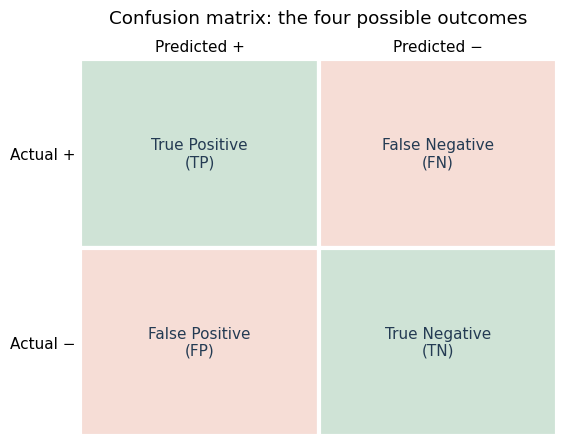

In [7]:
fig, ax = plt.subplots(figsize=(5.8,4.6))
cells=[["True Positive\n(TP)","False Negative\n(FN)"],["False Positive\n(FP)","True Negative\n(TN)"]]
cols=[["#cfe3d6","#f6ddd6"],["#f6ddd6","#cfe3d6"]]
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j,1-i),1,1,facecolor=cols[i][j],edgecolor="white",lw=3))
        ax.text(j+0.5,1-i+0.5,cells[i][j],ha="center",va="center",fontsize=11,color="#243b53")
ax.set_xlim(0,2); ax.set_ylim(0,2)
ax.set_xticks([0.5,1.5]); ax.set_xticklabels(["Predicted +","Predicted \u2212"])
ax.set_yticks([1.5,0.5]); ax.set_yticklabels(["Actual +","Actual \u2212"])
ax.xaxis.set_ticks_position("top"); ax.xaxis.set_label_position("top")
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Confusion matrix: the four possible outcomes", pad=26)
plt.tight_layout(); plt.show()


From these four boxes come three very useful numbers:

$$
\text{Precision} = \frac{TP}{TP + FP}
\qquad
\text{Recall} = \frac{TP}{TP + FN}
\qquad
\text{F1} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$

In plain words:

- **Precision** - *of everything I flagged as positive, how much really was?* (Few false alarms.)
- **Recall** - *of everything that truly was positive, how much did I catch?* (Few misses.)
- **F1** - a single score that balances the two.

Which one matters most depends on the job:

- Hunting for **defects** in materials? **Recall** - you really don't want to miss a bad part.
- Filtering **spam**? **Precision** - you don't want to bin a real email.

:::{tip}
When classes are imbalanced, look at precision, recall, and F1 **per class** - not just overall accuracy. A model can score 95% accuracy and still miss every rare defect.
:::

## Putting it together

- An **SVC** separates classes with a boundary that keeps the **widest margin**.
- The few points on the margin's edge - the **support vectors** - are all that matter.
- A **soft margin** (knob `C`) tolerates a few mistakes for a steadier boundary: pure **bias–variance**.
- When a straight boundary fails, a **kernel** lifts the data so a flat boundary works - done cheaply by the **kernel trick**.
- Pick `C`, `gamma`, and the kernel with **cross-validation** (or grid/random search, or Bayesian Optimization).
- In practice: **scale**, **stratify**, and mind **class imbalance**; then read **precision, recall, and F1**, not just accuracy.
- And always remember: a model inherits the **biases of its data**.

One sentence to carry with you: **an SVM finds the boundary with the most breathing room - and a kernel gives it room to bend.**

## Check your understanding

:::{dropdown} 1. What are "support vectors", and why are they special?
They are the few training points closest to the boundary, sitting on the edge of the margin. They alone determine where the boundary goes — moving any *other* point changes nothing.
:::

:::{dropdown} 2. You lower C toward a very small value. Does the margin get wider or narrower, and is the model more or less flexible?
The margin gets **wider** and the model gets **simpler / less flexible** (more bias, less variance). It tolerates more training mistakes in exchange for a steadier boundary.
:::

:::{dropdown} 3. Your two classes form rings-inside-rings. Which kernel should you reach for, and why?
An **RBF** (or polynomial) kernel. A linear kernel can only make straight boundaries; the RBF kernel effectively lifts the data into a higher dimension where a curved boundary can wrap around the inner ring.
:::

:::{dropdown} 4. What does the "kernel trick" save you from doing?
From ever building the high-dimensional coordinates. The kernel gives the *similarity* between points directly, so you get high-dimensional separating power at low-dimensional cost.
:::

:::{dropdown} 5. You're detecting rare defects (most parts are fine). Why might accuracy mislead you, and which metric matters most?
A model that predicts "no defect" for everything can score very high **accuracy** while catching **zero** defects. **Recall** matters most here — you don't want to miss a bad part.
:::

:::{seealso} Where these ideas come from
- Cortes, C. & Vapnik, V. (1995). *Support-Vector Networks.* Machine Learning, 20, 273–297 — the paper that introduced SVMs.
- The scikit-learn User Guide section on *Support Vector Machines* has practical `SVC` examples and a clear discussion of the `C` and `gamma` settings.

On algorithmic bias:
- Buolamwini, J. & Gebru, T. (2018). *Gender Shades.* Conference on Fairness, Accountability, and Transparency.
- Ribeiro, M. T., Singh, S. & Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier.* KDD (the husky-vs-wolf example).
- Kumagai, M. et al. (2022). *Effects of data bias on machine-learning-based material discovery using experimental property data.* Science and Technology of Advanced Materials: Methods, 2(1), 302–309.
:::

